Paso 1 Smoke test:

In [1]:
#Smoke test
import os
os.environ["HADOOP_USER_NAME"] = "root"
from pyspark.sql import SparkSession, functions as F, Window

spark = (SparkSession.builder.master("local[*]").appName("mitma-partA")
         .config("spark.driver.memory", "6g")
         .config("spark.sql.shuffle.partitions", "64")
         .config("spark.hadoop.dfs.replication", "2")
         .getOrCreate())

HDFS = "hdfs://namenode:9000"
RAW = f"{HDFS}/raw/viajes"
CURATED = f"{HDFS}/curated/viajes"
F_MIN, F_MAX = "2022-10-26", "2022-11-01"

In [2]:
   print(spark.sparkContext.uiWebUrl)

http://dafe6d44d408:4040


In [3]:
#tiene q salir 5
spark.range(5).write.mode("overwrite").parquet(f"{HDFS}/tmp/smoke")
print(spark.read.parquet(f"{HDFS}/tmp/smoke").count())   # tiene que salir 5

5


Paso 2: Leer los datos

In [4]:
schema = """fecha DATE, periodo INT, origen STRING, destino STRING, distancia STRING,
            actividad_origen STRING, actividad_destino STRING,
            estudio_origen_posible STRING, estudio_destino_posible STRING,
            residencia STRING, renta STRING, edad STRING, sexo STRING,
            viajes DOUBLE, viajes_km DOUBLE"""

viajes = (spark.read.schema(schema)
          .option("header", True).option("sep", "|")
          .option("dateFormat", "yyyyMMdd")
          .csv(RAW))

muni = (spark.read.option("header", True).option("sep", "|")
        .csv(f"{HDFS}/raw/zonificacion/nombres_municipios_ampliado.csv")
        .select(F.col("ID").alias("codigo"), F.col("name").alias("nombre"),
                "provincia", "ccaa"))

Paso 3: Inspecionar los datos

In [4]:
dia = (spark.read.schema(schema).option("header", True).option("sep", "|")
       .option("dateFormat", "yyyyMMdd")
       .csv(f"{HDFS}/raw/viajes/20221101_Viajes_municipios.csv"))
for c in ["distancia", "actividad_origen", "actividad_destino", "renta", "edad", "sexo"]:
    dia.groupBy(c).count().orderBy(F.desc("count")).show(15, truncate=False)

+---------+-------+
|distancia|count  |
+---------+-------+
|2-10     |4234443|
|10-50    |3015716|
|0.5-2    |1866596|
|>50      |816435 |
+---------+-------+

+----------------+-------+
|actividad_origen|count  |
+----------------+-------+
|no_frecuente    |3147794|
|frecuente       |2985392|
|casa            |2809438|
|trabajo_estudio |990566 |
+----------------+-------+

+-----------------+-------+
|actividad_destino|count  |
+-----------------+-------+
|casa             |3260846|
|frecuente        |2960822|
|no_frecuente     |2689165|
|trabajo_estudio  |1022357|
+-----------------+-------+

+-----+-------+
|renta|count  |
+-----+-------+
|10-15|6357147|
|<10  |2017803|
|>15  |1558240|
+-----+-------+

+------+-------+
|edad  |count  |
+------+-------+
|NA    |2961510|
|45-65 |2617502|
|25-45 |2055109|
|0-25  |1205023|
|65-100|1094046|
+------+-------+

+------+-------+
|sexo  |count  |
+------+-------+
|NA    |5082960|
|hombre|2547828|
|mujer |2302402|
+------+-------+



Paso 4: Limpieza

In [11]:
muni.show(3, truncate=False)
muni.groupBy("codigo").count().filter("count > 1").show()   # debe salir vacío, entonces esta perfecto

+--------+-----------------------------------+-----------+----------+
|codigo  |nombre                             |provincia  |ccaa      |
+--------+-----------------------------------+-----------+----------+
|01001   |Alegría-Dulantzi                   |Araba/Álava|País Vasco|
|01002   |Amurrio                            |Araba/Álava|País Vasco|
|01004_AM|Artziniega agregacion de municipios|Araba/Álava|País Vasco|
+--------+-----------------------------------+-----------+----------+
only showing top 3 rows
+------+-----+
|codigo|count|
+------+-----+
+------+-----+



In [5]:
limpio = (viajes
    .dropna(subset=["fecha", "periodo", "origen", "destino", "viajes"])
    .filter(F.col("periodo").between(0, 23))
    .filter(F.col("viajes") > 0)
    .filter(F.col("viajes_km").isNull() | (F.col("viajes_km") >= 0))
    .filter(F.col("fecha").between(F_MIN, F_MAX)))

print(viajes.count(), limpio.count())    # antes y después 

78340906 78340906


In [13]:
informe = viajes.agg(
    F.count("*").alias("filas"),
    F.sum(F.col("viajes").isNull().cast("int")).alias("viajes_nulo"),
    F.sum((F.col("viajes") <= 0).cast("int")).alias("viajes_no_positivo"),
    F.sum(F.col("viajes_km").isNull().cast("int")).alias("km_nulo"),
    F.sum((F.col("viajes_km") < 0).cast("int")).alias("km_negativo"),
    F.sum((~F.col("periodo").between(0, 23)).cast("int")).alias("periodo_fuera"),
    F.sum((~F.col("fecha").between("2022-10-26", "2022-11-01")).cast("int")).alias("fecha_fuera"))
informe.show(vertical=True)

-RECORD 0----------------------
 filas              | 78340906 
 viajes_nulo        | 0        
 viajes_no_positivo | 0        
 km_nulo            | 877      
 km_negativo        | 0        
 periodo_fuera      | 0        
 fecha_fuera        | 0        



Join con las provincias:

In [14]:
def con_nombre(df, col):
    m = muni.select(F.col("codigo").alias(col),
                    F.col("nombre").alias(f"nombre_{col}"),
                    F.col("provincia").alias(f"nombre_provincia_{col}"),
                    F.col("ccaa").alias(f"ccaa_{col}"))
    return df.join(F.broadcast(m), on=col, how="left")

curated = (con_nombre(con_nombre(limpio, "origen"), "destino")
           .withColumn("provincia_origen",  F.substring("origen", 1, 2))
           .withColumn("provincia_destino", F.substring("destino", 1, 2)))

curated.printSchema()
curated.show(5, truncate=False)

root
 |-- destino: string (nullable = true)
 |-- origen: string (nullable = true)
 |-- fecha: date (nullable = true)
 |-- periodo: integer (nullable = true)
 |-- distancia: string (nullable = true)
 |-- actividad_origen: string (nullable = true)
 |-- actividad_destino: string (nullable = true)
 |-- estudio_origen_posible: string (nullable = true)
 |-- estudio_destino_posible: string (nullable = true)
 |-- residencia: string (nullable = true)
 |-- renta: string (nullable = true)
 |-- edad: string (nullable = true)
 |-- sexo: string (nullable = true)
 |-- viajes: double (nullable = true)
 |-- viajes_km: double (nullable = true)
 |-- nombre_origen: string (nullable = true)
 |-- nombre_provincia_origen: string (nullable = true)
 |-- ccaa_origen: string (nullable = true)
 |-- nombre_destino: string (nullable = true)
 |-- nombre_provincia_destino: string (nullable = true)
 |-- ccaa_destino: string (nullable = true)
 |-- provincia_origen: string (nullable = true)
 |-- provincia_destino: strin

Escribir el Parquet

In [16]:
spark.conf.set("spark.sql.sources.partitionOverwriteMode", "dynamic")

(curated.write
        .mode("overwrite")
        .partitionBy("fecha")
        .parquet(CURATED))

In [6]:
c = spark.read.parquet(CURATED)

def extranjero(col):
    return F.col(col).rlike("^(PT|FR)") | (F.col(col) == "externo")

c = (c
  .withColumn("origen_extranjero",  extranjero("origen"))
  .withColumn("destino_extranjero", extranjero("destino"))
  .withColumn("nombre_origen",  F.coalesce("nombre_origen",  F.lit("ZONA EXTRANJERA")))
  .withColumn("nombre_destino", F.coalesce("nombre_destino", F.lit("ZONA EXTRANJERA")))
  .withColumn("provincia_origen",
              F.when(F.col("origen_extranjero"), F.lit("EXT")).otherwise(F.col("provincia_origen")))
  .withColumn("provincia_destino",
              F.when(F.col("destino_extranjero"), F.lit("EXT")).otherwise(F.col("provincia_destino")))
  .withColumn("nombre_provincia_origen",  F.coalesce("nombre_provincia_origen",  F.lit("Extranjero")))
  .withColumn("nombre_provincia_destino", F.coalesce("nombre_provincia_destino", F.lit("Extranjero")))
  .withColumn("ccaa_origen",  F.coalesce("ccaa_origen",  F.lit("Extranjero")))
  .withColumn("ccaa_destino", F.coalesce("ccaa_destino", F.lit("Extranjero"))))

In [18]:
c0 = spark.read.parquet(CURATED)     

def extranjero(col):
    return F.col(col).rlike("^(PT|FR)") | (F.col(col) == "externo")

sin_nombre = c0.filter(F.col("nombre_origen").isNull() | F.col("nombre_destino").isNull()).count()
raros = c0.filter((F.col("nombre_origen").isNull() & ~extranjero("origen")) |
                  (F.col("nombre_destino").isNull() & ~extranjero("destino"))).count()
print("sin nombre:", sin_nombre, "| sin nombre y no extranjero:", raros)

# detalle de los códigos sin nombre (para ver que son PT, FR y externo)
(c0.filter(F.col("nombre_destino").isNull())
   .groupBy("destino").count().orderBy(F.desc("count")).show(15, truncate=False))

sin nombre: 704364 | sin nombre y no extranjero: 0
+-------+-----+
|destino|count|
+-------+-----+
|PT170  |35350|
|PT11A  |34196|
|FRI15  |32195|
|FRJ15  |30909|
|FR101  |20737|
|externo|17164|
|PT186  |14326|
|PT112  |9162 |
|PT150  |9077 |
|FRI12  |7734 |
|FRJ23  |7521 |
|FR102  |6775 |
|FRI13  |6660 |
|FR107  |6141 |
|PT11E  |5866 |
+-------+-----+
only showing top 15 rows


In [19]:
ccaa_raros = c0.filter((F.col("ccaa_origen").isNull() & ~extranjero("origen")) |
                       (F.col("ccaa_destino").isNull() & ~extranjero("destino"))).count()
n_ccaa = c0.filter(F.col("ccaa_origen").isNotNull()).select("ccaa_origen").distinct().count()
print("sin CCAA y no extranjero:", ccaa_raros, "| CCAA distintas (origen):", n_ccaa)

sin CCAA y no extranjero: 0 | CCAA distintas (origen): 19


Averiguamos que hay unas que no se les asigna nombre de la tabla municipios ya que son de Portugal o Francia, por lo tanto agregamos dos columnas extra sobre si es extrajero o no el destino y origen

In [29]:
n_filas = c0.count()
n_fechas = c0.select("fecha").distinct().count()

calidad = spark.createDataFrame(
    [(n_filas, n_fechas, sin_nombre, raros, ccaa_raros, n_ccaa, round(100 * sin_nombre / n_filas, 2))],
    "filas_curadas LONG, fechas INT, sin_nombre LONG, sin_nombre_no_extranjero LONG, "
    "sin_ccaa_no_extranjero LONG, ccaa_distintas INT, pct_sin_nombre DOUBLE")
calidad.show(truncate=False)
calidad.coalesce(1).write.mode("overwrite").option("header", True).csv(f"{HDFS}/results/calidad_join")
calidad.show(truncate=False)
calidad.coalesce(1).write.mode("overwrite").option("header", True).csv(f"{HDFS}/results/calidad_join")

+-------------+------+----------+------------------------+----------------------+--------------+--------------+
|filas_curadas|fechas|sin_nombre|sin_nombre_no_extranjero|sin_ccaa_no_extranjero|ccaa_distintas|pct_sin_nombre|
+-------------+------+----------+------------------------+----------------------+--------------+--------------+
|78340906     |7     |704364    |0                       |0                     |19            |0.9           |
+-------------+------+----------+------------------------+----------------------+--------------+--------------+

+-------------+------+----------+------------------------+----------------------+--------------+--------------+
|filas_curadas|fechas|sin_nombre|sin_nombre_no_extranjero|sin_ccaa_no_extranjero|ccaa_distintas|pct_sin_nombre|
+-------------+------+----------+------------------------+----------------------+--------------+--------------+
|78340906     |7     |704364    |0                       |0                     |19            |0.9    

In [7]:
#Incluyendo dos columnas si es extrajero o no el destino y origen
c = spark.read.parquet(CURATED)

def extranjero(col):
    return F.col(col).rlike("^(PT|FR)") | (F.col(col) == "externo")

c = (c
  .withColumn("origen_extranjero",  extranjero("origen"))
  .withColumn("destino_extranjero", extranjero("destino"))
  .withColumn("nombre_origen",  F.coalesce("nombre_origen",  F.lit("ZONA EXTRANJERA")))
  .withColumn("nombre_destino", F.coalesce("nombre_destino", F.lit("ZONA EXTRANJERA")))
  .withColumn("provincia_origen",
              F.when(F.col("origen_extranjero"), F.lit("EXT")).otherwise(F.col("provincia_origen")))
  .withColumn("provincia_destino",
              F.when(F.col("destino_extranjero"), F.lit("EXT")).otherwise(F.col("provincia_destino"))))

In [8]:
c.filter("fecha = '2022-11-01'").explain()

== Physical Plan ==
*(1) Project [destino#126, origen#127, periodo#128, distancia#129, actividad_origen#130, actividad_destino#131, estudio_origen_posible#132, estudio_destino_posible#133, residencia#134, renta#135, edad#136, sexo#137, viajes#138, viajes_km#139, nombre_origen#152, nombre_provincia_origen#141, ccaa_origen#142, nombre_destino#153, nombre_provincia_destino#144, ccaa_destino#145, CASE WHEN origen_extranjero#150 THEN EXT ELSE provincia_origen#146 END AS provincia_origen#154, CASE WHEN destino_extranjero#151 THEN EXT ELSE provincia_destino#147 END AS provincia_destino#155, fecha#148, origen_extranjero#150, destino_extranjero#151]
+- *(1) Project [destino#126, origen#127, periodo#128, distancia#129, actividad_origen#130, actividad_destino#131, estudio_origen_posible#132, estudio_destino_posible#133, residencia#134, renta#135, edad#136, sexo#137, viajes#138, viajes_km#139, coalesce(nombre_origen#140, ZONA EXTRANJERA) AS nombre_origen#152, nombre_provincia_origen#141, ccaa_orig

Como se puede ver arriba, los origenes y destinos que no se lograron unir con la tabla auxiliar es porque su codigo es fuera de España. Es en Francia.

Como podemos ver arriba ahora tebemos EXT como una categoria mas:

In [9]:
# 1) EXT aparece como una categoría más
(c.groupBy("provincia_origen").count()
   .filter(F.col("provincia_origen") == "EXT").show())

# 2) Cuántas categorías hay en total (provincias + EXT)
print("categorías origen :", c.select("provincia_origen").distinct().count())
print("categorías destino:", c.select("provincia_destino").distinct().count())

# 3) EXT == filas extranjeras, y ninguna provincia nula
print("EXT origen == origen_extranjero:",
      c.filter(F.col("provincia_origen") == "EXT").count() == c.filter("origen_extranjero").count())
print("EXT destino == destino_extranjero:",
      c.filter(F.col("provincia_destino") == "EXT").count() == c.filter("destino_extranjero").count())
print("provincias nulas:",
      c.filter(F.col("provincia_origen").isNull() | F.col("provincia_destino").isNull()).count())

+----------------+------+
|provincia_origen| count|
+----------------+------+
|             EXT|360384|
+----------------+------+

categorías origen : 53
categorías destino: 53
EXT origen == origen_extranjero: True
EXT destino == destino_extranjero: True
provincias nulas: 0


Tiempo con CVS:

In [24]:
%%time
q = lambda df: df.groupBy("fecha").agg(F.sum("viajes").alias("viajes")).orderBy("fecha")
q(viajes).collect()

CPU times: user 138 ms, sys: 23.9 ms, total: 162 ms
Wall time: 40.4 s


[Row(fecha=datetime.date(2022, 10, 26), viajes=139756287.4732185),
 Row(fecha=datetime.date(2022, 10, 27), viajes=140015789.60663596),
 Row(fecha=datetime.date(2022, 10, 28), viajes=143436053.52149144),
 Row(fecha=datetime.date(2022, 10, 29), viajes=119395430.63943443),
 Row(fecha=datetime.date(2022, 10, 30), viajes=106292592.42973603),
 Row(fecha=datetime.date(2022, 10, 31), viajes=128806621.1730693),
 Row(fecha=datetime.date(2022, 11, 1), viajes=106107027.74200705)]

Tiempo con Parquet:

In [25]:
%%time
q(c0).collect()

CPU times: user 20.6 ms, sys: 14.3 ms, total: 34.8 ms
Wall time: 2.53 s


[Row(fecha=datetime.date(2022, 10, 26), viajes=139756287.4732125),
 Row(fecha=datetime.date(2022, 10, 27), viajes=140015789.6066459),
 Row(fecha=datetime.date(2022, 10, 28), viajes=143436053.521497),
 Row(fecha=datetime.date(2022, 10, 29), viajes=119395430.6394304),
 Row(fecha=datetime.date(2022, 10, 30), viajes=106292592.42973249),
 Row(fecha=datetime.date(2022, 10, 31), viajes=128806621.17308673),
 Row(fecha=datetime.date(2022, 11, 1), viajes=106107027.74200378)]

In [27]:
comp = spark.createDataFrame(
    [("csv", "6.4 GB", 43.8, 40.4), ("parquet", "839.0 MB", 2.77, 2.53)],
    "formato STRING, tamano STRING, seg_1a_ejecucion DOUBLE, seg_2a_ejecucion DOUBLE")
comp.show(truncate=False)
comp.coalesce(1).write.mode("overwrite").option("header", True).csv(f"{HDFS}/results/comparacion_formatos")

+-------+--------+----------------+----------------+
|formato|tamano  |seg_1a_ejecucion|seg_2a_ejecucion|
+-------+--------+----------------+----------------+
|csv    |6.4 GB  |43.8            |40.4            |
|parquet|839.0 MB|2.77            |2.53            |
+-------+--------+----------------+----------------+



Map reduce con RDD en spark:

In [23]:
import time

def parse(line):
    c = line.split("|")
    if len(c) < 15:
        return []
    try:
        v = float(c[13])
    except ValueError:
        return []
    return [(c[3], v)] if v > 0 else []

t = time.perf_counter()
res = (spark.sparkContext.textFile(RAW)
       .flatMap(parse)
       .reduceByKey(lambda a, b: a + b)
       .collect())
print("segundos:", round(time.perf_counter() - t, 2), "| destinos:", len(res))

segundos: 65.6 | destinos: 2681


In [24]:
hd = (spark.sparkContext.textFile(f"{HDFS}/results/mr_streaming_destino_7d_run2")
      .map(lambda l: l.split("\t"))
      .map(lambda p: (p[0], float(p[1])))
      .collectAsMap())
rd = dict(res)

print("destinos Hadoop:", len(hd), "| destinos Spark:", len(rd))
print("mismos destinos:", set(hd) == set(rd))
print("diferencia máxima:", max(abs(hd[k] - rd[k]) for k in hd))

destinos Hadoop: 2681 | destinos Spark: 2681
mismos destinos: True
diferencia máxima: 5.960464477539063e-08


In [25]:
comp_mr = spark.createDataFrame(
    [("hadoop_intento_limpio", 331.0), ("hadoop_run1_con_fallo", 819.8),
     ("hadoop_run2_total", 1681.5), ("spark_rdd_1a", 57.41), ("spark_rdd_2a", 65.6)],
    "implementacion STRING, segundos DOUBLE")
comp_mr.show(truncate=False)
comp_mr.coalesce(1).write.mode("overwrite").option("header", True).csv(f"{HDFS}/results/comparacion_mr_spark")

+---------------------+--------+
|implementacion       |segundos|
+---------------------+--------+
|hadoop_intento_limpio|331.0   |
|hadoop_run1_con_fallo|819.8   |
|hadoop_run2_total    |1681.5  |
|spark_rdd_1a         |57.41   |
|spark_rdd_2a         |65.6    |
+---------------------+--------+



Preguntas:
1. ¿Cuáles son los 10 flujos entre CCAA distintas con más viajes y qué porcentaje del total suponen?-Agrupación
2. ¿Cuáles son los 3 municipios que más viajes reciben cada día a nivel nacional?- Ventana(ranking)
3. Para cada municipio y día, ¿cuánto se desvía su número
de viajes respecto a la media de ese municipio en los 7 días? )

In [10]:
#1. 
nac = c.filter(~F.col("origen_extranjero") & ~F.col("destino_extranjero"))

total_inter = (nac.filter(F.col("ccaa_origen") != F.col("ccaa_destino"))
                  .agg(F.sum("viajes")).first()[0])

q1 = (nac.filter(F.col("ccaa_origen") != F.col("ccaa_destino"))
         .groupBy("ccaa_origen", "ccaa_destino")
         .agg(F.sum("viajes").alias("viajes"))
         .withColumn("pct_interccaa", F.round(100 * F.col("viajes") / total_inter, 2))
         .orderBy(F.col("viajes").desc()))
q1.show(10, truncate=False)

+--------------------+--------------------+------------------+-------------+
|ccaa_origen         |ccaa_destino        |viajes            |pct_interccaa|
+--------------------+--------------------+------------------+-------------+
|Comunidad de Madrid |Castilla-La Mancha  |2221859.0774858356|13.34        |
|Castilla-La Mancha  |Comunidad de Madrid |2203500.8475939105|13.23        |
|Comunitat Valenciana|Región de Murcia    |637561.4004178563 |3.83         |
|Región de Murcia    |Comunitat Valenciana|636698.2161976091 |3.82         |
|Comunidad de Madrid |Castilla y León     |606590.5549899839 |3.64         |
|Castilla y León     |Comunidad de Madrid |586550.0052902625 |3.52         |
|Cataluña            |Aragón              |283333.7845019639 |1.7          |
|Aragón              |Cataluña            |281225.22985601204|1.69         |
|País Vasco          |Cantabria           |264128.6825473128 |1.59         |
|Cantabria           |País Vasco          |263133.7983918798 |1.58         |

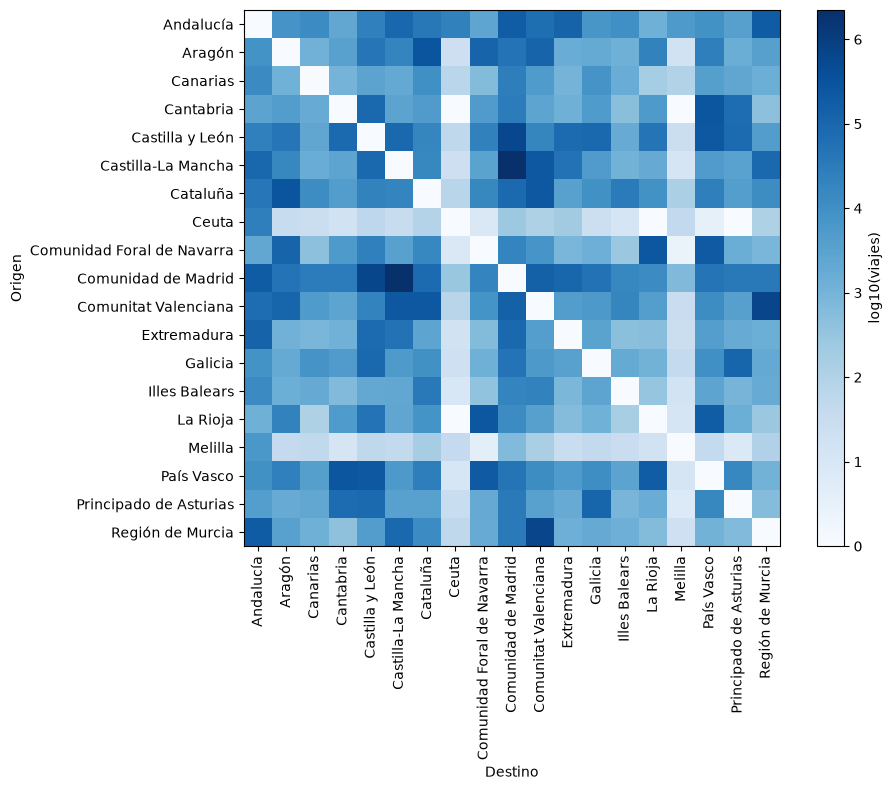

In [11]:
import numpy as np
import matplotlib.pyplot as plt

m = (nac.filter(F.col("ccaa_origen") != F.col("ccaa_destino"))
        .groupBy("ccaa_origen", "ccaa_destino")
        .agg(F.sum("viajes").alias("viajes"))
        .toPandas()
        .pivot(index="ccaa_origen", columns="ccaa_destino", values="viajes")
        .fillna(0))

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(np.log10(m.values + 1), cmap="Blues")
ax.set_xticks(range(len(m.columns))); ax.set_xticklabels(m.columns, rotation=90)
ax.set_yticks(range(len(m.index)));   ax.set_yticklabels(m.index)
ax.set_xlabel("Destino"); ax.set_ylabel("Origen")
fig.colorbar(im, label="log10(viajes)")
plt.tight_layout()
plt.savefig("matriz_od_ccaa.png", dpi=150)

In [12]:
#Agrupación por municipio de destino
diario_dest = (c.filter(~F.col("destino_extranjero"))
                .groupBy("fecha", "destino", "nombre_destino")
                .agg(F.sum("viajes").alias("viajes")))

In [13]:
#2. Venatana (ranking)
w = Window.partitionBy("fecha").orderBy(F.col("viajes").desc())
q2 = (diario_dest.withColumn("puesto", F.rank().over(w))
                 .filter("puesto <= 3")
                 .orderBy("fecha", "puesto"))
q2.show(21, truncate=False)

+----------+-------+--------------+--------------------+------+
|fecha     |destino|nombre_destino|viajes              |puesto|
+----------+-------+--------------+--------------------+------+
|2022-10-26|28079  |Madrid        |1.0674975799000077E7|1     |
|2022-10-26|08019  |Barcelona     |5528293.234000061   |2     |
|2022-10-26|46250  |València      |2530314.231000061   |3     |
|2022-10-27|28079  |Madrid        |1.0672287821000036E7|1     |
|2022-10-27|08019  |Barcelona     |5464173.1720000915  |2     |
|2022-10-27|46250  |València      |2536546.663999976   |3     |
|2022-10-28|28079  |Madrid        |1.0454252684999978E7|1     |
|2022-10-28|08019  |Barcelona     |5387058.059999975   |2     |
|2022-10-28|46250  |València      |2546218.231999969   |3     |
|2022-10-29|28079  |Madrid        |7952294.919909113   |1     |
|2022-10-29|08019  |Barcelona     |4088561.6000925098  |2     |
|2022-10-29|46250  |València      |2011510.3151454004  |3     |
|2022-10-30|28079  |Madrid        |74221

In [56]:
q2.explain("formatted")

== Physical Plan ==
AdaptiveSparkPlan (17)
+- Sort (16)
   +- Exchange (15)
      +- Filter (14)
         +- Window (13)
            +- WindowGroupLimit (12)
               +- Sort (11)
                  +- Exchange (10)
                     +- WindowGroupLimit (9)
                        +- Sort (8)
                           +- HashAggregate (7)
                              +- Exchange (6)
                                 +- HashAggregate (5)
                                    +- Project (4)
                                       +- Filter (3)
                                          +- Project (2)
                                             +- Scan parquet  (1)


(1) Scan parquet 
Output [4]: [destino#636, viajes#648, nombre_destino#653, fecha#658]
Batched: true
Location: InMemoryFileIndex [hdfs://namenode:9000/curated/viajes]
ReadSchema: struct<destino:string,viajes:double,nombre_destino:string>

(2) Project
Output [5]: [destino#636, viajes#648, nombre_destino#653, fecha#658, (

In [14]:
#3. Window(comparación)
w2 = Window.partitionBy("destino")
q3 = (diario_dest
      .withColumn("media_muni", F.avg("viajes").over(w2))
      .withColumn("desviacion", F.col("viajes") - F.col("media_muni"))
      .withColumn("desv_pct", F.round(100 * F.col("desviacion") / F.col("media_muni"), 1)))

(q3.filter(F.col("media_muni") >= 1000)
   .orderBy(F.abs("desv_pct").desc())
   .show(10, truncate=False))

+----------+--------+-------------------------------------------+------------------+------------------+------------------+--------+
|fecha     |destino |nombre_destino                             |viajes            |media_muni        |desviacion        |desv_pct|
+----------+--------+-------------------------------------------+------------------+------------------+------------------+--------+
|2022-11-01|27032   |Monterroso                                 |23291.00999999998 |9137.061214320174 |14153.948785679806|154.9   |
|2022-11-01|03903   |Montesinos, Los                            |1576.8569999999993|8031.393949575958 |-6454.536949575959|-80.4   |
|2022-10-30|29100   |Yunquera                                   |5738.275499999973 |3324.0059285714246|2414.2695714285487|72.6    |
|2022-10-29|29100   |Yunquera                                   |5546.3989999999985|3324.0059285714246|2222.393071428574 |66.9    |
|2022-10-28|06033_AM|Casas de Don Pedro agregacion de municipios|5582.260000

In [59]:
%%time
q2.collect()

CPU times: user 12.6 ms, sys: 1.18 ms, total: 13.8 ms
Wall time: 6.88 s


[Row(fecha=datetime.date(2022, 10, 26), destino='28079', nombre_destino='Madrid', viajes=10674975.799000077, puesto=1),
 Row(fecha=datetime.date(2022, 10, 26), destino='08019', nombre_destino='Barcelona', viajes=5528293.234000061, puesto=2),
 Row(fecha=datetime.date(2022, 10, 26), destino='46250', nombre_destino='València', viajes=2530314.231000061, puesto=3),
 Row(fecha=datetime.date(2022, 10, 27), destino='28079', nombre_destino='Madrid', viajes=10672287.821000036, puesto=1),
 Row(fecha=datetime.date(2022, 10, 27), destino='08019', nombre_destino='Barcelona', viajes=5464173.1720000915, puesto=2),
 Row(fecha=datetime.date(2022, 10, 27), destino='46250', nombre_destino='València', viajes=2536546.663999976, puesto=3),
 Row(fecha=datetime.date(2022, 10, 28), destino='28079', nombre_destino='Madrid', viajes=10454252.684999978, puesto=1),
 Row(fecha=datetime.date(2022, 10, 28), destino='08019', nombre_destino='Barcelona', viajes=5387058.059999975, puesto=2),
 Row(fecha=datetime.date(2022, 

In [50]:
plan = q2._jdf.queryExecution().explainString(
    spark._jvm.org.apache.spark.sql.execution.ExplainMode.fromString("formatted"))
open("d_q2_explain.txt", "w").write(plan)
print(plan[:300])

== Physical Plan ==
AdaptiveSparkPlan (40)
+- == Final Plan ==
   ResultQueryStage (24)
   +- * Sort (23)
      +- AQEShuffleRead (22), coalesced
         +- ShuffleQueryStage (21), Statistics(sizeInBytes=1448.0 B, rowCount=21)
            +- Exchange (20)
               +- * Filter (19)
           


In [ ]:
%%time
q3.collect()

Aregando optimización con cache

In [60]:
diario_cache = diario_dest.cache()

In [61]:
%%time
diario_cache.count()

CPU times: user 13.2 ms, sys: 1.99 ms, total: 15.2 ms
Wall time: 9.77 s


17937

In [62]:
q2c = (diario_cache.withColumn("puesto", F.rank().over(w))
                   .filter("puesto <= 3").orderBy("fecha", "puesto"))


In [ ]:

q3c = (diario_cache.withColumn("media_muni", F.avg("viajes").over(w2))
                   .withColumn("desviacion", F.col("viajes") - F.col("media_muni"))
                   .withColumn("desv_pct", F.round(100 * F.col("desviacion") / F.col("media_muni"), 1)))

In [63]:
%%time
q2c.collect()

CPU times: user 6.15 ms, sys: 1.94 ms, total: 8.09 ms
Wall time: 755 ms


[Row(fecha=datetime.date(2022, 10, 26), destino='28079', nombre_destino='Madrid', viajes=10674975.799000077, puesto=1),
 Row(fecha=datetime.date(2022, 10, 26), destino='08019', nombre_destino='Barcelona', viajes=5528293.234000061, puesto=2),
 Row(fecha=datetime.date(2022, 10, 26), destino='46250', nombre_destino='València', viajes=2530314.231000061, puesto=3),
 Row(fecha=datetime.date(2022, 10, 27), destino='28079', nombre_destino='Madrid', viajes=10672287.821000036, puesto=1),
 Row(fecha=datetime.date(2022, 10, 27), destino='08019', nombre_destino='Barcelona', viajes=5464173.1720000915, puesto=2),
 Row(fecha=datetime.date(2022, 10, 27), destino='46250', nombre_destino='València', viajes=2536546.663999976, puesto=3),
 Row(fecha=datetime.date(2022, 10, 28), destino='28079', nombre_destino='Madrid', viajes=10454252.684999978, puesto=1),
 Row(fecha=datetime.date(2022, 10, 28), destino='08019', nombre_destino='Barcelona', viajes=5387058.059999975, puesto=2),
 Row(fecha=datetime.date(2022, 

In [ ]:
%%time
q3c.collect()

In [49]:
T_COUNT = 7.22

comp_cache = spark.createDataFrame(
    [("P2 sin cache", 8.27),
     ("P3 sin cache", 8.58),
     ("TOTAL sin cache", 16.85),
     ("Crear cache (count, una vez)", float(T_COUNT)),
     ("P2 con cache", 0.276),
     ("P3 con cache", 1.04),
     ("TOTAL con cache (count + P2 + P3)", round(T_COUNT + 0.276 + 1.04, 2))],
    "escenario STRING, segundos DOUBLE")
comp_cache.show(truncate=False)
comp_cache.coalesce(1).write.mode("overwrite").option("header", True).csv(f"{HDFS}/results/comparacion_cache")

+---------------------------------+--------+
|escenario                        |segundos|
+---------------------------------+--------+
|P2 sin cache                     |8.27    |
|P3 sin cache                     |8.58    |
|TOTAL sin cache                  |16.85   |
|Crear cache (count, una vez)     |7.22    |
|P2 con cache                     |0.276   |
|P3 con cache                     |1.04    |
|TOTAL con cache (count + P2 + P3)|8.54    |
+---------------------------------+--------+



In [54]:
   diario_cache.unpersist()

DataFrame[fecha: date, destino: string, nombre_destino: string, viajes: double]

Resultados de las preguntas analíticas:

In [16]:
q1_fin = q1.withColumn("viajes", F.round("viajes").cast("long"))
q2_fin = q2.withColumn("viajes", F.round("viajes").cast("long"))

def a_enteros(df):
    return (df.withColumn("viajes",     F.round("viajes").cast("long"))
              .withColumn("media_muni", F.round("media_muni").cast("long"))
              .withColumn("desviacion", F.round("desviacion").cast("long")))

q3_fin     = a_enteros(q3)
q3_top_fin = a_enteros(q3.filter(F.col("media_muni") >= 10000)
                         .orderBy(F.abs("desv_pct").desc())
                         .limit(20))

for nombre, df in [("q1_flujos_ccaa", q1_fin),
                   ("q2_top3_destinos", q2_fin),
                   ("q3_desviacion_municipio", q3_fin),
                   ("q3_top20_desviaciones", q3_top_fin)]:
    (df.coalesce(1).write.mode("overwrite")
       .option("header", True).csv(f"{HDFS}/results/{nombre}"))